In [1]:
import numpy as np
import matplotlib.pyplot as plt 
import pandas as pd


In [3]:
df = pd.read_csv("cluster_data.csv")
print(df)
print(df.columns.tolist())

     Feature 1  Feature 2
0     2.698582  -0.672960
1    -0.128113   4.355952
2     2.509049   5.773146
3    -1.518276   3.444886
4    -0.072283   2.883769
..         ...        ...
495  10.303693  -4.378493
496  -0.730000   6.254563
497  -3.478708   2.257991
498  -2.081214   2.447245
499   3.359415   5.248267

[500 rows x 2 columns]
['Feature 1', 'Feature 2']


In [4]:
df.drop_duplicates()
df.fillna(df.mean(numeric_only=True))

,Feature 1,Feature 2
0,2.698582,-0.672960
1,-0.128113,4.355952
2,2.509049,5.773146
3,-1.518276,3.444886
4,-0.072283,2.883769
...,...,...
495,10.303693,-4.378493
496,-0.730000,6.254563
497,-3.478708,2.257991
498,-2.081214,2.447245


In [6]:
x = df[['Feature 1', 'Feature 2']]

In [9]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

x_scaled = scaler.fit_transform(x)


In [11]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

kmeans.fit(x_scaled)

labels = kmeans.labels_

print("Cluster labels:")
print(labels)

Cluster labels:
[1 1 0 1 1 2 1 2 1 1 0 1 1 0 1 2 1 2 1 1 1 2 1 1 1 0 1 1 0 1 1 0 1 0 1 1 1
 2 2 2 0 2 1 1 1 1 2 1 1 0 0 2 1 1 2 1 2 2 0 1 1 2 1 1 0 0 1 0 1 1 1 1 1 2
 1 1 1 1 1 1 1 0 0 1 2 1 2 1 1 1 1 0 0 1 2 1 1 1 0 0 1 0 0 1 0 1 2 1 1 1 1
 1 1 2 2 0 0 0 1 2 2 0 1 0 1 1 2 1 0 0 0 1 0 2 0 2 2 2 0 1 1 0 1 1 1 2 2 0
 1 1 0 0 0 1 1 0 1 1 0 1 0 2 1 0 1 1 1 1 2 1 1 0 2 2 1 0 1 0 1 0 1 0 0 2 1
 2 1 1 0 2 0 1 2 1 1 1 1 2 0 0 1 0 0 0 0 1 2 1 1 1 2 0 1 0 2 0 2 1 1 1 1 1
 2 2 2 0 1 2 2 1 1 1 0 0 0 1 0 1 2 0 1 1 0 2 1 1 0 0 1 2 2 0 1 1 1 0 1 1 1
 0 2 1 0 1 1 1 2 1 1 1 1 0 1 1 0 1 0 1 0 0 1 1 1 1 0 1 0 1 0 2 1 1 0 1 1 2
 0 1 2 0 2 1 1 1 0 1 2 1 1 0 2 0 1 2 1 1 0 2 2 2 0 0 1 1 1 0 2 2 1 1 0 1 1
 1 0 1 1 0 1 2 1 0 1 2 1 1 1 0 1 1 1 1 1 1 1 1 0 1 1 2 1 1 2 0 0 1 1 1 0 0
 1 1 2 1 1 1 2 1 0 1 2 2 0 2 2 0 0 2 1 0 0 0 1 2 2 2 2 1 0 1 0 1 2 1 1 1 1
 0 1 0 2 1 2 0 1 1 2 0 1 1 2 1 0 1 1 1 1 0 1 0 0 2 0 1 0 1 1 0 1 0 1 2 0 0
 0 1 1 1 0 0 0 1 2 1 1 1 2 1 0 1 2 0 0 2 1 1 0 1 1 1 2 1 0 1 0 1 0 2 1 2 1
 2 1 2 0 

In [12]:
df["Cluster"] = labels



   Feature 1  Feature 2  Cluster
0   2.698582  -0.672960        1
1  -0.128113   4.355952        1
2   2.509049   5.773146        0
3  -1.518276   3.444886        1
4  -0.072283   2.883769        1


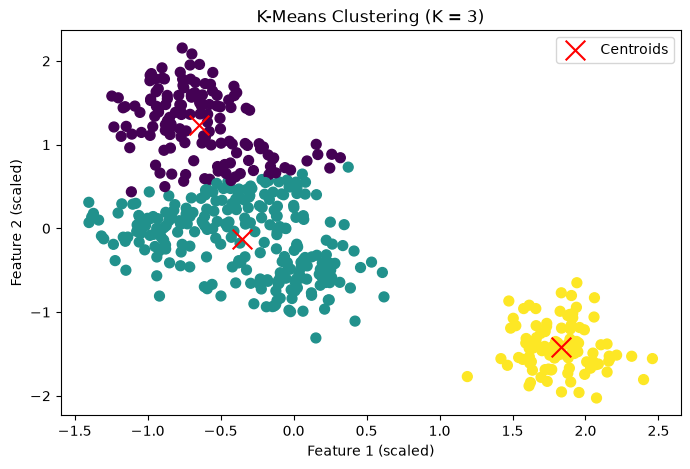

In [15]:
plt.figure(figsize=(8, 5))

plt.scatter(
    x_scaled[:, 0],
    x_scaled[:, 1],
    c=labels,
    cmap="viridis",
    s=50
)

centers = kmeans.cluster_centers_

plt.scatter(
    centers[:, 0],
    centers[:, 1],
    marker="x",
    s=200,
    color="red",
    label="Centroids"
)

plt.xlabel("Feature 1 (scaled)")
plt.ylabel("Feature 2 (scaled)")
plt.title("K-Means Clustering (K = 3)")
plt.legend()
plt.show()